In [ ]:
!pip -q install \
transformers \
timm \
sentencepiece \
accelerate \
datasets \
scikit-learn \
pandas \
pillow \
tqdm

In [ ]:
import os
import copy
import glob
import random
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)

from transformers import (
    AutoImageProcessor,
    AutoTokenizer,
    AutoModel,
    SiglipVisionModel,
    get_cosine_schedule_with_warmup,
)
from torch.amp import GradScaler

device = torch.device("cuda:0")
print(device)

cuda:0


In [ ]:
import transformers
print(transformers.__version__)

5.13.1


In [ ]:
torch.__version__

'2.11.0+cu128'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [ ]:
TRAIN_IMAGES = "/content/drive/MyDrive/shared task/Train/train_images"
TRAIN_CSV = "/content/drive/MyDrive/shared task/Train/train_labels.csv"

IMAGE_MODEL = "google/siglip-base-patch16-512"
XLM_MODEL = "xlm-roberta-base"

In [ ]:
df = pd.read_csv(TRAIN_CSV)

df = df.rename(columns={
    "Image_id": "image",
    "Text": "text",
    "Level1": "label1",
    "Level2": "label2"
})

df["text"] = df["text"].fillna("").astype(str).str.strip()

df.head()

,image,text,label1,label2
0,0,• கர்நாடகாவில் ரஜினியின் காலா படம் வெளியா முதல...,Troll/Oppose,Troll/Oppose Against Person
1,1,Thalapathy Vijay Thiruchchi Varugai...\nThiruc...,Support/Praise,Support for person
2,2,"""அண்ண சொல்லுங்க.\n#GET OU MODI\n#GET OUT STALI...",Troll/Oppose,Troll/Oppose Against Party
3,3,சீமான் கவுண்டமணி மரண கலாய்\nதேங்காய அங்கேயே வை...,Troll/Oppose,Troll/Oppose Against Person
4,4,TOI - LINE OF NO CONTROL \nKAMAL HAASAN START...,Support/Praise,Support for party


In [ ]:
level1_encoder = LabelEncoder()
level2_encoder = LabelEncoder()

df["label1_id"] = level1_encoder.fit_transform(df.label1)
df["label2_id"] = level2_encoder.fit_transform(df.label2)

print("Level 1 classes:", list(level1_encoder.classes_))
print("Level 2 classes:", list(level2_encoder.classes_))

# label2 determines label1
support_idx = [i for i, c in enumerate(level1_encoder.classes_)
               if "support" in c.lower()][0]

troll_idx = [i for i, c in enumerate(level1_encoder.classes_)
             if "troll" in c.lower() or "oppose" in c.lower()][0]

label1_from_label2 = df["label2"].apply(
    lambda x: support_idx if x.startswith("Support") else troll_idx
)

# Find disagreements
mismatch_mask = df["label1_id"] != label1_from_label2
mismatches = df[mismatch_mask].copy()

print(f"\nFound {len(mismatches)} label mismatches.\n")

for idx, row in mismatches.iterrows():
    print("=" * 80)
    print(f"Row Index : {idx}")

    if "image" in row:
        print(f"Image ID  : {row['image']}")
    elif "image_name" in row:
        print(f"Image ID  : {row['image_name']}")
    elif "image_id" in row:
        print(f"Image ID  : {row['image_id']}")

    print(f"Level1 Label : {row['label1']}")
    print(f"Level2 Label : {row['label2']}")

    print("\nOCR Text:")
    print(row["text"])

print("\nOverriding labels...")
df["label1_id"] = label1_from_label2

Level 1 classes: ['Support/Praise', 'Troll/Oppose']
Level 2 classes: ['Support for party', 'Support for person', 'Troll/Oppose Against Party', 'Troll/Oppose Against Person']

Found 5 label mismatches.

Row Index : 125
Image ID  : 125
Level1 Label : Troll/Oppose
Level2 Label : Support for party

OCR Text:
அமைச்சர் பதவியா? ஜாமீனா?
செந்தில் பாலாஜி

பெண்களை இழிவாக பேசி மாட்டிக்கொண்டவர்
பொன்முடி

சொத்துக்குவிப்பு வழக்கு
துரைமுருகன்

சொத்துக்குவிப்பு வழக்கு
எம்.ஆர்.கே. பன்னீர்செல்வம்

WELL DONE BOYS
Row Index : 176
Image ID  : 176
Level1 Label : Support/Praise
Level2 Label : Troll/Oppose Against Person

OCR Text:
மூன்று மாதத்துல வாரத்துக்கு ஒரு நாள் பிரச்சாரம்!! ஜனவரி 9 ஜனவரிகள படத்தை வைத்து ஒரு சபமம்... அப்புறம் மூன்றாவது மாதத்து மாறாடு! அடுத்தது சட்டமன்ற தேர்தல்! 2026 - ல சபமம் இருக்கு
Row Index : 467
Image ID  : 467
Level1 Label : Support/Praise
Level2 Label : Troll/Oppose Against Person

OCR Text:
TN Elections 2026 Exit Polls (TOI): TVK Vijay (TVK Leader) – TVK 125–155, DMK 25–45, ADMK 1

In [ ]:
image_processor = AutoImageProcessor.from_pretrained(IMAGE_MODEL)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        512,
        scale=(0.9,1.0)
    ),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.02
    )
])

val_transform = None

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

In [ ]:
img = Image.open(os.path.join(TRAIN_IMAGES, "001.jpg")).convert("RGB")

print("Original:", img.size)

processed = image_processor(img, return_tensors="pt")

print("Processed:", processed["pixel_values"].shape)

Original: (1350, 1688)
Processed: torch.Size([1, 3, 512, 512])


In [ ]:
class MemeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_name = f"{int(row.image):03d}.jpg"
        image = Image.open(os.path.join(TRAIN_IMAGES, image_name)).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return {
            "image": image,
            "text": row.text,
            "label1": row.label1_id}


def collate_fn(batch):
    images = [x["image"] for x in batch]
    image_inputs = image_processor(images, return_tensors="pt")

    return {
        "pixel_values": image_inputs["pixel_values"],
        "label1": torch.tensor([x["label1"] for x in batch])
    }

In [ ]:
class MemeClassifier(nn.Module):

    def __init__(self, image_encoder):
        super().__init__()

        self.image_encoder = image_encoder

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(768, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        self.level1_head = nn.Linear(256, 2)

    def forward(self, pixel_values):

        # SigLIP image encoder
        image_outputs = self.image_encoder(pixel_values=pixel_values)

        # Global image representation
        image_features = image_outputs.pooler_output

        # Classification head
        features = self.classifier(image_features)

        level1_logits = self.level1_head(features)

        return {
            "level1": level1_logits
        }

In [ ]:
def build_model():
    """Fresh encoders + fresh classifier head -- call once per fold so folds
    don't share weights/optimizer state with each other."""

    image_encoder = SiglipVisionModel.from_pretrained(IMAGE_MODEL)

    for p in image_encoder.parameters():
        p.requires_grad = False
    for layer in image_encoder.encoder.layers[-4:]:
        for p in layer.parameters():
            p.requires_grad = True

    model = MemeClassifier(image_encoder).to(device)
    return model


def build_optimizer_scheduler(model, train_loader, epochs):
    optimizer = torch.optim.AdamW(
        [
            {"params": model.image_encoder.parameters(), "lr": 1e-5},
            {"params": model.classifier.parameters(), "lr": 3e-5},
            {"params": model.level1_head.parameters(), "lr": 3e-5}
        ],
        weight_decay=0.01,
        betas=(0.9, 0.999)
    )

    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )

    return optimizer, scheduler


def class_weights_for(train_df, col, n_classes, device):
    """Inverse-frequency weights computed fresh from this fold's train split
    -- the ONLY imbalance-correction mechanism in this pipeline."""
    counts = (
        train_df[col].value_counts()
        .reindex(range(n_classes), fill_value=1)   # avoid div-by-zero if a class is missing in a fold
        .sort_index()
        .values
    )
    w = counts.sum() / counts
    w = w / w.mean()
    return torch.tensor(w, dtype=torch.float32, device=device)


def build_criteria(train_df):
    crit_level1 = nn.CrossEntropyLoss(
        weight=class_weights_for(train_df, "label1_id", 2, device),
        label_smoothing=0.05
    )
    return crit_level1

LAMBDA_LEVEL1 = 0.3

In [ ]:
def macro_prf(labels, preds):
    """Macro precision/recall/F1 in one call, used everywhere below so every
    reported score comes with precision and recall alongside F1, not just F1."""
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    return {"precision": precision, "recall": recall, "f1": f1}


def train_one_epoch(model, loader, optimizer, scheduler, scaler, criteria):
    crit_l1 = criteria

    model.train()
    running_loss = 0

    preds1, labels1 = [], []

    for batch in loader:
        pixel_values = batch["pixel_values"].to(device)

        label1 = batch["label1"].to(device)

        optimizer.zero_grad()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = model(pixel_values)
            loss_l1 = crit_l1(out["level1"], label1)

            loss = LAMBDA_LEVEL1 * loss_l1

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item()
        preds1.extend(out["level1"].argmax(1).cpu().numpy())
        labels1.extend(label1.cpu().numpy())

    m1 = macro_prf(labels1, preds1)

    return running_loss / len(loader), m1


@torch.no_grad()
def validate(
    model,
    loader,
    criteria):
    crit_l1 = criteria

    model.eval()
    running_loss = 0

    preds1, labels1 = [], []

    for batch in loader:
        pixel_values = batch["pixel_values"].to(device)

        label1 = batch["label1"].to(device)

        out = model(
            pixel_values
        )
        loss_l1 = crit_l1(out["level1"], label1)

        loss = LAMBDA_LEVEL1 * loss_l1

        running_loss += loss.item()
        preds1.extend(out["level1"].argmax(1).cpu().numpy())
        labels1.extend(label1.cpu().numpy())

    m1 = macro_prf(labels1, preds1)

    return (
    running_loss / len(loader),
    m1,
    labels1,
    preds1,
)

In [ ]:
K_FOLDS = 5
EPOCHS_PER_FOLD = 20
PATIENCE = 4
BATCH_SIZE = 8

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

fold_scores = []
oof_l1_labels = np.full(len(df), -1)
oof_l1_preds = np.full(len(df), -1)

for fold, (train_idx, val_idx) in enumerate(skf.split(df, df["label1_id"])):

    print("=" * 70)
    print(f"FOLD {fold + 1}/{K_FOLDS}")
    print("=" * 70)

    train_df_fold = df.iloc[train_idx].reset_index(drop=True)
    val_df_fold = df.iloc[val_idx].reset_index(drop=True)

    train_dataset = MemeDataset(train_df_fold, transform=train_transform)
    val_dataset = MemeDataset(val_df_fold, transform=val_transform)

    class_counts = train_df_fold["label1_id"].value_counts().reindex(range(2), fill_value=1)
    sample_weights = train_df_fold["label1_id"].map(1.0 / class_counts).values

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_fn,
        num_workers=2
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=2
    )

    model = build_model()
    optimizer, scheduler = build_optimizer_scheduler(model, train_loader, EPOCHS_PER_FOLD)
    scaler = GradScaler("cuda")
    criteria = build_criteria(train_df_fold)

    best_score = 0
    counter = 0
    best_state = None

    for epoch in range(EPOCHS_PER_FOLD):
        train_loss, train_m1 = train_one_epoch(
            model, train_loader, optimizer, scheduler, scaler, criteria
        )

        val_loss, val_m1, val_l1_labels, val_l1_preds = validate(
            model, val_loader, criteria
        )

        print(
            f"Epoch {epoch+1:2d}"
            f" | Train L1 F1 {train_m1['f1']:.3f}"
            f" || Val L1 P/R/F1 {val_m1['precision']:.3f}/{val_m1['recall']:.3f}/{val_m1['f1']:.3f}"
        )

        if val_m1["f1"] > best_score:
            best_score = val_m1["f1"]
            counter = 0
            best_state = copy.deepcopy(model.state_dict())
            best_val_l1_labels, best_val_l1_preds = val_l1_labels, val_l1_preds
        else:
            counter += 1
            if counter >= PATIENCE:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    model.eval()

    torch.save(best_state, f"best_model_fold{fold}.pt")
    fold_scores.append(best_score)

    oof_l1_labels[val_idx] = best_val_l1_labels
    oof_l1_preds[val_idx] = best_val_l1_preds

    print(f"Fold {fold+1} best val L1 macro-F1...")

    del model, optimizer, scheduler
    torch.cuda.empty_cache()

fold_scores = np.array(fold_scores)
print("=" * 70)
print(f"K-Fold results: {fold_scores.round(4)}")
print(f"Mean macro-F1: {fold_scores.mean():.4f}  |  Std: {fold_scores.std():.4f}")
print("=" * 70)

FOLD 1/5


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Epoch  1 | Train L1 F1 0.544 || Val L1 P/R/F1 0.807/0.837/0.819
Epoch  2 | Train L1 F1 0.814 || Val L1 P/R/F1 0.850/0.868/0.858
Epoch  3 | Train L1 F1 0.883 || Val L1 P/R/F1 0.902/0.893/0.897
Epoch  4 | Train L1 F1 0.922 || Val L1 P/R/F1 0.902/0.893/0.897
Epoch  5 | Train L1 F1 0.959 || Val L1 P/R/F1 0.896/0.904/0.900
Epoch  6 | Train L1 F1 0.983 || Val L1 P/R/F1 0.893/0.909/0.901
Epoch  7 | Train L1 F1 0.991 || Val L1 P/R/F1 0.886/0.906/0.895
Epoch  8 | Train L1 F1 0.992 || Val L1 P/R/F1 0.902/0.893/0.897
Epoch  9 | Train L1 F1 0.997 || Val L1 P/R/F1 0.879/0.902/0.889
Epoch 10 | Train L1 F1 0.998 || Val L1 P/R/F1 0.886/0.886/0.886
Early stopping
Fold 1 best val L1 macro-F1...
FOLD 2/5


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

...

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Epoch  1 | Train L1 F1 0.547 || Val L1 P/R/F1 0.755/0.786/0.765
Epoch  2 | Train L1 F1 0.808 || Val L1 P/R/F1 0.814/0.865/0.828
Epoch  3 | Train L1 F1 0.879 || Val L1 P/R/F1 0.869/0.890/0.878
Epoch  4 | Train L1 F1 0.931 || Val L1 P/R/F1 0.897/0.905/0.901
Epoch  5 | Train L1 F1 0.959 || Val L1 P/R/F1 0.903/0.880/0.890
Epoch  6 | Train L1 F1 0.981 || Val L1 P/R/F1 0.898/0.871/0.883
Epoch  7 | Train L1 F1 0.984 || Val L1 P/R/F1 0.882/0.898/0.889
Epoch  8 | Train L1 F1 0.992 || Val L1 P/R/F1 0.879/0.883/0.881
Early stopping
Fold 4 best val L1 macro-F1...
FOLD 5/5


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Epoch  1 | Train L1 F1 0.593 || Val L1 P/R/F1 0.804/0.800/0.802
Epoch  2 | Train L1 F1 0.804 || Val L1 P/R/F1 0.870/0.878/0.874
Epoch  3 | Train L1 F1 0.880 || Val L1 P/R/F1 0.873/0.873/0.873
Epoch  4 | Train L1 F1 0.928 || Val L1 P/R/F1 0.871/0.904/0.885
Epoch  5 | Train L1 F1 0.959 || Val L1 P/R/F1 0.916/0.920/0.918
Epoch  6 | Train L1 F1 0.976 || Val L1 P/R/F1 0.930/0.865/0.891
Epoch  7 | Train L1 F1 0.992 || Val L1 P/R/F1 0.859/0.902/0.875
Epoch  8 | Train L1 F1 0.995 || Val L1 P/R/F1 0.938/0.907/0.921
Epoch  9 | Train L1 F1 0.997 || Val L1 P/R/F1 0.895/0.904/0.899
Epoch 10 | Train L1 F1 0.997 || Val L1 P/R/F1 0.898/0.918/0.907
Epoch 11 | Train L1 F1 0.998 || Val L1 P/R/F1 0.919/0.915/0.917
Epoch 12 | Train L1 F1 0.998 || Val L1 P/R/F1 0.928/0.918/0.923
Epoch 13 | Train L1 F1 1.000 || Val L1 P/R/F1 0.919/0.915/0.917
Epoch 14 | Train L1 F1 1.000 || Val L1 P/R/F1 0.919/0.915/0.917
Epoch 15 | Train L1 F1 1.000 || Val L1 P/R/F1 0.911/0.911/0.911
Epoch 16 | Train L1 F1 1.000 || Val L1 P

## Saving Outputs

In [ ]:
np.save("oof_l1_preds.npy", oof_l1_preds)
np.save("oof_l1_labels.npy", oof_l1_labels)

In [ ]:
import os
import zipfile

extensions = {".pt"}

zip_filename = "/content/model_outputs.zip"

search_dir = "/content"

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(search_dir):

        dirs[:] = [
            d for d in dirs
            if not d.startswith(".")
            and d not in {
                "drive",
                "sample_data",
                ".cache",
                "hf_home",
                "__pycache__",
            }
        ]

        for file in files:

            if file == os.path.basename(zip_filename):
                continue

            if os.path.splitext(file)[1].lower() in extensions:

                filepath = os.path.join(root, file)

                # Preserve relative paths inside the zip
                arcname = os.path.relpath(filepath, search_dir)

                zipf.write(filepath, arcname)
                print(f"Added: {arcname}")

print(f"\nCreated {zip_filename}")

Added: best_model_fold2.pt
Added: best_model_fold1.pt
Added: best_model_fold4.pt
Added: best_model_fold3.pt
Added: best_model_fold0.pt

Created /content/model_outputs.zip


In [ ]:
import os; os.system("cp model_outputs.zip /content/drive/MyDrive/")

0

## Compose level2 from level1 (SigLIP) + target (XLM-R)

In [ ]:
oof_l1_labels = np.load("/content/oof_l1_labels.npy")
oof_l1_preds = np.load("/content/oof_l1_preds.npy")

In [ ]:
COMBO_TO_LEVEL2 = {
    ("Support/Praise", "Party"): "Support for party",
    ("Support/Praise", "Person"): "Support for person",
    ("Troll/Oppose", "Party"): "Troll/Oppose Against Party",
    ("Troll/Oppose", "Person"): "Troll/Oppose Against Person",
}

entity_map = {
    "Support for party": "Party", "Support for person": "Person",
    "Troll/Oppose Against Party": "Party", "Troll/Oppose Against Person": "Person",
}
df["entity_name"] = df["label2"].map(entity_map)
assert df["entity_name"].isna().sum() == 0

target_encoder = LabelEncoder()
df["target_id"] = target_encoder.fit_transform(df["entity_name"])
TARGET_NAMES = {idx: name for idx, name in enumerate(target_encoder.classes_)}
LEVEL1_NAMES = {idx: name for idx, name in enumerate(level1_encoder.classes_)}

print("Target classes:", list(target_encoder.classes_))

Target classes: ['Party', 'Person']


In [ ]:
MAX_LEN = 128

target_tokenizer = AutoTokenizer.from_pretrained(XLM_MODEL)


class TargetDataset(Dataset):
    """Now multimodal -- returns image + text + target, so the target head
    can see party flags/logos/symbols that never get typed out in the
    caption, not just text."""

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_name = f"{int(row.image):03d}.jpg"
        image = Image.open(os.path.join(TRAIN_IMAGES, image_name)).convert("RGB")
        if self.transform:
            image = self.transform(image)

        text = row.text if row.text.strip() else "(no caption)"

        return {
            "image": image,
            "text": text,
            "target": row.target_id,
        }


def collate_fn_target(batch):
    images = [x["image"] for x in batch]
    texts = [x["text"] for x in batch]

    image_inputs = image_processor(images, return_tensors="pt")
    encoded = target_tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt",
    )

    return {
        "pixel_values": image_inputs["pixel_values"],
        "input_ids": encoded["input_ids"],
        "attention_mask": encoded["attention_mask"],
        "target": torch.tensor([x["target"] for x in batch]),
    }

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

In [ ]:
class TargetClassifier(nn.Module):

    def __init__(self, image_encoder, text_encoder):
        super().__init__()

        self.image_encoder = image_encoder
        self.text_encoder = text_encoder

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(768 + 768, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        self.target_head = nn.Linear(512, 2)

    def forward(self, pixel_values, input_ids, attention_mask):
        image_features = self.image_encoder(pixel_values=pixel_values).pooler_output

        text_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)

        mask = attention_mask.unsqueeze(-1).float()
        text_features = (text_out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1e-9)

        fused = torch.cat([image_features, text_features], dim=1)
        features = self.classifier(fused)
        target_logits = self.target_head(features)

        return {"target": target_logits}

In [ ]:
def build_target_model():
    image_encoder = SiglipVisionModel.from_pretrained(IMAGE_MODEL)
    for p in image_encoder.parameters():
        p.requires_grad = False
    for layer in image_encoder.encoder.layers[-4:]:
        for p in layer.parameters():
            p.requires_grad = True

    text_encoder = AutoModel.from_pretrained(XLM_MODEL)
    for p in text_encoder.parameters():
        p.requires_grad = False
    for layer in text_encoder.encoder.layer[-4:]:
        for p in layer.parameters():
            p.requires_grad = True

    model = TargetClassifier(image_encoder, text_encoder).to(device)
    return model


def build_target_optimizer_scheduler(model, train_loader, epochs):
    optimizer = torch.optim.AdamW(
        [
            {"params": model.image_encoder.parameters(), "lr": 5e-6},
            {"params": model.text_encoder.parameters(), "lr": 5e-6},
            {"params": model.classifier.parameters(), "lr": 2e-5},
            {"params": model.target_head.parameters(), "lr": 2e-5},
        ],
        weight_decay=0.01,
        betas=(0.9, 0.999),
    )

    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.15 * total_steps),
        num_training_steps=total_steps,
    )

    return optimizer, scheduler


def build_target_criteria():
    return nn.CrossEntropyLoss(label_smoothing=0.05)

In [ ]:
def train_one_epoch_target(model, loader, optimizer, scheduler, scaler, criteria):
    model.train()
    running_loss = 0
    preds, labels = [], []

    for batch in loader:
        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        target = batch["target"].to(device)

        optimizer.zero_grad()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = model(pixel_values, input_ids, attention_mask)
            loss = criteria(out["target"], target)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item()
        preds.extend(out["target"].argmax(1).cpu().numpy())
        labels.extend(target.cpu().numpy())

    m = macro_prf(labels, preds)
    return running_loss / len(loader), m


@torch.no_grad()
def validate_target(model, loader, criteria):
    model.eval()
    running_loss = 0
    preds, labels = [], []
    probs = []

    for batch in loader:
        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        target = batch["target"].to(device)

        out = model(pixel_values, input_ids, attention_mask)
        loss = criteria(out["target"], target)

        running_loss += loss.item()
        preds.extend(out["target"].argmax(1).cpu().numpy())
        labels.extend(target.cpu().numpy())
        probs.extend(torch.softmax(out["target"], dim=1).cpu().numpy())

    m = macro_prf(labels, preds)
    return running_loss / len(loader), m, labels, preds, np.array(probs)

In [ ]:
K_FOLDS_TARGET = 5
EPOCHS_PER_FOLD_TARGET = 20
PATIENCE_TARGET = 4
BATCH_SIZE_TARGET = 8

skf_target = StratifiedKFold(n_splits=K_FOLDS_TARGET, shuffle=True, random_state=SEED)

fold_scores_target = []
oof_target_labels = np.full(len(df), -1)
oof_target_preds = np.full(len(df), -1)
oof_target_probs = np.full((len(df), 2), np.nan)

for fold, (train_idx, val_idx) in enumerate(skf_target.split(df, df["target_id"])):

    print("=" * 70)
    print(f"TARGET FOLD {fold + 1}/{K_FOLDS_TARGET}")
    print("=" * 70)

    train_df_fold = df.iloc[train_idx].reset_index(drop=True)
    val_df_fold = df.iloc[val_idx].reset_index(drop=True)

    train_dataset = TargetDataset(train_df_fold, transform=train_transform)
    val_dataset = TargetDataset(val_df_fold, transform=val_transform)

    class_counts = train_df_fold["target_id"].value_counts().reindex(range(2), fill_value=1)
    sample_weights = train_df_fold["target_id"].map(1.0 / class_counts).values
    sampler = torch.utils.data.WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True,
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE_TARGET, sampler=sampler,
        collate_fn=collate_fn_target, num_workers=2,
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE_TARGET, shuffle=False,
        collate_fn=collate_fn_target, num_workers=2,
    )

    model = build_target_model()
    optimizer, scheduler = build_target_optimizer_scheduler(model, train_loader, EPOCHS_PER_FOLD_TARGET)
    scaler = GradScaler("cuda")
    criteria = build_target_criteria()

    best_score = 0
    counter = 0
    best_state = None

    for epoch in range(EPOCHS_PER_FOLD_TARGET):
        train_loss, train_m = train_one_epoch_target(model, train_loader, optimizer, scheduler, scaler, criteria)
        val_loss, val_m, val_labels, val_preds, val_probs = validate_target(model, val_loader, criteria)

        print(
            f"Epoch {epoch+1:2d}"
            f" | Train F1 {train_m['f1']:.3f}"
            f" || Val P/R/F1 {val_m['precision']:.3f}/{val_m['recall']:.3f}/{val_m['f1']:.3f}"
        )

        if val_m["f1"] > best_score:
            best_score = val_m["f1"]
            counter = 0
            best_state = copy.deepcopy(model.state_dict())
            best_val_labels, best_val_preds = val_labels, val_preds
            best_val_probs = val_probs

        else:
            counter += 1
            if counter >= PATIENCE_TARGET:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    model.eval()

    torch.save(best_state, f"best_target_model_fold{fold}.pt")
    fold_scores_target.append(best_score)

    oof_target_labels[val_idx] = best_val_labels
    oof_target_preds[val_idx] = best_val_preds
    oof_target_probs[val_idx] = best_val_probs

    print(f"Fold {fold+1} best val target macro-F1: {best_score:.4f}")

    del model, optimizer, scheduler
    torch.cuda.empty_cache()

fold_scores_target = np.array(fold_scores_target)
print("=" * 70)
print(f"K-Fold target results: {fold_scores_target.round(4)}")
print(f"Mean macro-F1: {fold_scores_target.mean():.4f}  |  Std: {fold_scores_target.std():.4f}")
print("=" * 70)

np.save("oof_target_preds.npy", oof_target_preds)
np.save("oof_target_labels.npy", oof_target_labels)

## RUN

                             Support for party  Support for person  \
Support for party                           62                  22   
Support for person                          24                 124   
Troll/Oppose Against Party                   7                   6   
Troll/Oppose Against Person                  9                  16   

                             Troll/Oppose Against Party  \
Support for party                                     7   
Support for person                                    3   
Troll/Oppose Against Party                           76   
Troll/Oppose Against Person                          74   

                             Troll/Oppose Against Person  
Support for party                                      8  
Support for person                                    26  
Troll/Oppose Against Party                            57  
Troll/Oppose Against Person                          448  


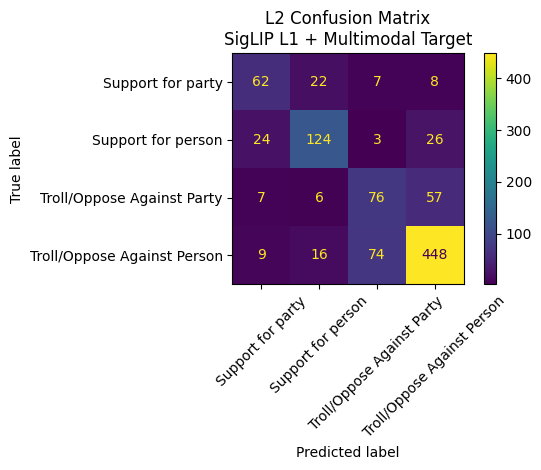


LEVEL 1
                precision    recall  f1-score     support
Support/Praise   0.859259  0.840580  0.849817  276.000000
Troll/Oppose     0.937053  0.945166  0.941092  693.000000
accuracy         0.915377  0.915377  0.915377    0.915377
macro avg        0.898156  0.892873  0.895454  969.000000
weighted avg     0.914895  0.915377  0.915094  969.000000

LEVEL 2
                             precision    recall  f1-score     support
Support for party             0.607843  0.626263  0.616915   99.000000
Support for person            0.738095  0.700565  0.718841  177.000000
Troll/Oppose Against Party    0.475000  0.520548  0.496732  146.000000
Troll/Oppose Against Person   0.831169  0.819013  0.825046  547.000000
accuracy                      0.732714  0.732714  0.732714    0.732714
macro avg                     0.663027  0.666597  0.664384  969.000000
weighted avg                  0.737687  0.732714  0.734915  969.000000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

###########################################################################
# LOAD OOF FILES
###########################################################################

oof_l1_labels = np.load("oof_l1_labels.npy")
oof_l1_preds = np.load("oof_l1_preds.npy")

oof_target_labels = np.load("oof_target_labels.npy")
oof_target_preds = np.load("oof_target_preds.npy")

###########################################################################
# RECOMPOSE LEVEL 2
###########################################################################

oof_l2_preds_target = level2_encoder.transform([
    COMBO_TO_LEVEL2[
        (
            LEVEL1_NAMES[oof_l1_preds[i]],
            TARGET_NAMES[oof_target_preds[i]]
        )
    ]
    for i in range(len(df))
])

###########################################################################
# CONFUSION MATRIX
###########################################################################

cm = confusion_matrix(
    df["label2_id"],
    oof_l2_preds_target
)

print(
    pd.DataFrame(
        cm,
        index=level2_encoder.classes_,
        columns=level2_encoder.classes_
    )
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=level2_encoder.classes_
)

disp.plot(
    values_format="d",
    xticks_rotation=45
)

plt.title(
    "L2 Confusion Matrix\nSigLIP L1 + Multimodal Target"
)

plt.tight_layout()

plt.savefig(
    "l2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

###########################################################################
# L1 REPORT
###########################################################################

l1_report = classification_report(
    oof_l1_labels,
    oof_l1_preds,
    target_names=level1_encoder.classes_,
    digits=4,
    output_dict=True,
)

l1_report_df = pd.DataFrame(l1_report).transpose()

l1_report_df.to_csv(
    "L1_classification_report.csv"
)

print("\nLEVEL 1")
print(l1_report_df)

###########################################################################
# L2 REPORT
###########################################################################

l2_report = classification_report(
    df["label2_id"],
    oof_l2_preds_target,
    target_names=level2_encoder.classes_,
    digits=4,
    output_dict=True,
)

l2_report_df = pd.DataFrame(l2_report).transpose()

l2_report_df.to_csv(
    "L2_classification_report.csv"
)

print("\nLEVEL 2")
print(l2_report_df)

## Test

In [ ]:
import os
import copy
import numpy as np
import pandas as pd

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

###########################################################################
# TEST PATHS
###########################################################################

TEST_IMAGES = "/content/drive/MyDrive/shared task/Test/test_images"
TEST_CSV = "/content/drive/MyDrive/shared task/Test/test-unlabelled.csv"

###########################################################################

test_df = pd.read_csv(TEST_CSV)

test_df = test_df.rename(columns={
    "Image_id": "image",
    "Text": "text"
})

test_df["text"] = (
    test_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print(test_df.head())
print(len(test_df))

   image                                               text
0      0  குதிரை வேகத்தில் செயல்படும் அரசே தவிர.. குதிரை...
1      1  “உதனால் அனைத்து நாம் என்ன தீக்குச்சியா?”\nஉதயச...
2      2  வா...போ..ங்கோ...போன்றவை பாசத்தில்‌\n\nபேசுவது....
3      3  என்னிக்கு உங்க மூஞ்சில முழிச்சனோ..\nஇன்னிக்கு ...
4      4  INTERNATIONAL YOGA DAY\n\n ONE YEAR OF CAPTAIN...
244


In [ ]:
class TestDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_name = f"{int(row.image):03d}.jpg"

        image = Image.open(
            os.path.join(TEST_IMAGES, image_name)
        ).convert("RGB")

        text = row.text

        if text == "":
            text = "(no caption)"

        return {
            "image": image,
            "text": text,
            "image_id": row.image
        }

In [ ]:
def collate_fn_test(batch):

    images = [x["image"] for x in batch]
    texts = [x["text"] for x in batch]

    image_inputs = image_processor(
        images,
        return_tensors="pt"
    )

    encoded = target_tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

    return {

        "pixel_values": image_inputs["pixel_values"],

        "input_ids": encoded["input_ids"],

        "attention_mask": encoded["attention_mask"],

        "image_id": [x["image_id"] for x in batch]
    }

In [ ]:
BATCH_SIZE = 8

test_dataset = TestDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn_test,
    num_workers=2,
)

print(len(test_loader))

31


In [ ]:
###################
# LEVEL 1 ENSEMBLE
###################

L1_MODEL_DIR = "/content"

l1_fold_probs = []

image_ids = None

for fold in range(5):

    print(f"Running L1 Fold {fold}")

    model = build_model()

    ckpt = torch.load(
        os.path.join(
            L1_MODEL_DIR,
            f"best_model_fold{fold}.pt"
        ),
        map_location="cpu"
    )

    model.load_state_dict(ckpt)

    model.to(device)
    model.eval()

    fold_probs = []
    ids = []

    with torch.no_grad():

        for batch in test_loader:

            pixel_values = batch["pixel_values"].to(device)

            logits = model(pixel_values)["level1"]

            probs = torch.softmax(logits, dim=1)

            fold_probs.append(probs.cpu())

            ids.extend(batch["image_id"])

    if image_ids is None:
        image_ids = ids

    l1_fold_probs.append(torch.cat(fold_probs))

    del model
    del ckpt

    torch.cuda.empty_cache()

l1_mean_probs = torch.stack(l1_fold_probs).mean(0)

oof_l1_test_preds = l1_mean_probs.argmax(1).numpy()

print("Finished L1 ensemble")

Running L1 Fold 0


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Running L1 Fold 1


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

...

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Running L1 Fold 4


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Finished L1 ensemble


In [ ]:
###################
# TARGET ENSEMBLE
##################

TARGET_MODEL_DIR = "/content/drive/MyDrive/model_outputs"

target_fold_probs = []

for fold in range(5):

    print(f"Running Target Fold {fold}")

    model = build_target_model()

    ckpt = torch.load(
        os.path.join(
            TARGET_MODEL_DIR,
            f"best_target_model_fold{fold}.pt"
        ),
        map_location="cpu"
    )

    model.load_state_dict(ckpt)

    model.to(device)
    model.eval()

    fold_probs = []

    with torch.no_grad():

        for batch in test_loader:

            pixel_values = batch["pixel_values"].to(device)

            input_ids = batch["input_ids"].to(device)

            attention_mask = batch["attention_mask"].to(device)

            logits = model(
                pixel_values,
                input_ids,
                attention_mask
            )["target"]

            probs = torch.softmax(logits, dim=1)

            fold_probs.append(probs.cpu())

    target_fold_probs.append(torch.cat(fold_probs))

    del model
    del ckpt

    torch.cuda.empty_cache()

target_mean_probs = torch.stack(target_fold_probs).mean(0)

oof_target_test_preds = target_mean_probs.argmax(1).numpy()

print("Finished Target ensemble")

Running Target Fold 0


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

...

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-512
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished Target ensemble


In [ ]:
####################
# CREATE SUBMISSION
####################

level1_predictions = [
    LEVEL1_NAMES[p]
    for p in oof_l1_test_preds
]

target_predictions = [
    TARGET_NAMES[p]
    for p in oof_target_test_preds
]

level2_predictions = [
    COMBO_TO_LEVEL2[(l1, target)]
    for l1, target in zip(level1_predictions, target_predictions)
]

submission = pd.DataFrame({
    "Image_id": image_ids,
    "Level1": level1_predictions,
    "Level2": level2_predictions,
})

submission.to_csv(
    "submission.csv",
    index=False
)

print(submission.head())

print("\nSaved submission.csv")

print("\nLevel1 distribution")
print(submission["Level1"].value_counts())

print("\nLevel2 distribution")
print(submission["Level2"].value_counts())

   Image_id          Level1                       Level2
0         0  Support/Praise           Support for person
1         1  Support/Praise           Support for person
2         2    Troll/Oppose  Troll/Oppose Against Person
3         3    Troll/Oppose  Troll/Oppose Against Person
4         4    Troll/Oppose  Troll/Oppose Against Person

Saved submission.csv

Level1 distribution
Level1
Troll/Oppose      179
Support/Praise     65
Name: count, dtype: int64

Level2 distribution
Level2
Troll/Oppose Against Person    140
Support for person              44
Troll/Oppose Against Party      39
Support for party               21
Name: count, dtype: int64


In [ ]:
import os; os.system("cp submission.csv /content/drive/MyDrive/")
os.system("cp oof_l1_labels.npy /content/drive/MyDrive/")
os.system("cp oof_l1_preds.npy /content/drive/MyDrive/")

0